# Part 3: Linear Regression 2.1

**Objective 2, HIT140 Assessment 3.**

**Analytic question:** how well can information available **before kickoff** predict the **goal difference** between
two teams in a FIFA World Cup 2026 match, and which pre match factors matter most?

| Item | Detail |
|---|---|
| Input | `data/processed/candidates_2_1.csv` from Part 2 (104 matches) |
| Target | `goal_difference`, extra time included, penalty shootouts excluded |
| Variables | chosen from 23 pre match candidates by EDA and a documented selection procedure (Blocks 3 to 6) |
| Output | the final dataset `data/processed/wc2026_goal_difference.csv` with **exactly 8 explanatory variables** |

**Workflow.** Split the data first; select the variables using the training set only; explore the selected
variables; fit and evaluate the model against a baseline; interpret it; check the regression assumptions;
compare viable alternative models; and validate the selection procedure itself. Run the cells from top to bottom.

## 1. Libraries and paths

In [1]:
from pathlib import Path
# The notebook sits inside a Part_ folder; the project root is one level up.
ROOT = Path.cwd().parent if Path.cwd().name.startswith("Part_") else Path.cwd()
RAW = ROOT / "data" / "raw"              # files collected from FIFA (Part 1)
PROCESSED = ROOT / "data" / "processed"  # modelling datasets (Part 2)
OUT = Path.cwd()                          # this part's own tables/ and figures/
(OUT / "tables").mkdir(exist_ok=True)
(OUT / "figures").mkdir(exist_ok=True)
print("Project root:", ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from IPython.display import display
from sklearn.linear_model import LinearRegression, PoissonRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, KFold, GroupShuffleSplit, GroupKFold
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan, linear_rainbow
from statsmodels.stats.stattools import durbin_watson, jarque_bera

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE, GREY = "#2a78d6", "#8a8984"

Project root: /home/claude/A3


## 2. Load the candidate table from Part 2

In [2]:
TARGET = "goal_difference"
ID_COLS = ['match_number', 'date', 'stage', 'team1', 'team2', 'team1_goals', 'team2_goals']
df = pd.read_csv(PROCESSED / "candidates_2_1.csv")
CANDIDATES = list(df.columns[8:])
print("Rows:", len(df), "| candidate variables:", len(CANDIDATES))
print(CANDIDATES)

Rows: 104 | candidate variables: 23
['fifa_points_diff', 'fifa_rank_diff', 'wc_experience_diff', 'strong_confederation_diff', 'host_advantage', 'rest_days_diff', 'prev_goals_for_diff', 'prev_goals_against_diff', 'prev_xg_diff', 'prev_xg_against_diff', 'prev_shots_diff', 'prev_shots_on_target_diff', 'prev_possession_diff', 'prev_pass_accuracy_diff', 'prev_corners_diff', 'prev_shots_against_diff', 'prev_finishing_diff', 'prev_xg_per_shot_diff', 'prev_pressures_diff', 'prev_forced_turnovers_diff', 'prev_linebreaks_diff', 'prev_distance_km_diff', 'prev_high_speed_km_diff']


## 3. Split into training and test sets (before any selection)
Choosing variables with the full data would let the test set influence the model and make the test result
too optimistic. So the split comes first, and Blocks 4 to 6 use **only the training set**.

In [3]:
# Hold out 20% of the matches BEFORE choosing variables, so the test set never influences any decision.
train_idx, test_idx = train_test_split(np.arange(len(df)), test_size=0.2, random_state=42)

train, test = df.iloc[train_idx].copy(), df.iloc[test_idx].copy()
print("Training rows:", len(train), "| Test rows:", len(test))

Training rows: 83 | Test rows: 21


## 4. Variable selection, step 1: relevance
Rank every candidate by the strength of its linear relationship with the target, measured as the absolute
Pearson correlation |r| **in the training set**.

,r with target (train),|r|
fifa_points_diff,0.654,0.654
fifa_rank_diff,-0.627,0.627
prev_xg_against_diff,-0.545,0.545
wc_experience_diff,0.536,0.536
prev_linebreaks_diff,0.486,0.486
prev_pass_accuracy_diff,0.476,0.476
prev_possession_diff,0.470,0.470
prev_shots_against_diff,-0.435,0.435
prev_goals_against_diff,-0.425,0.425
prev_shots_diff,0.326,0.326


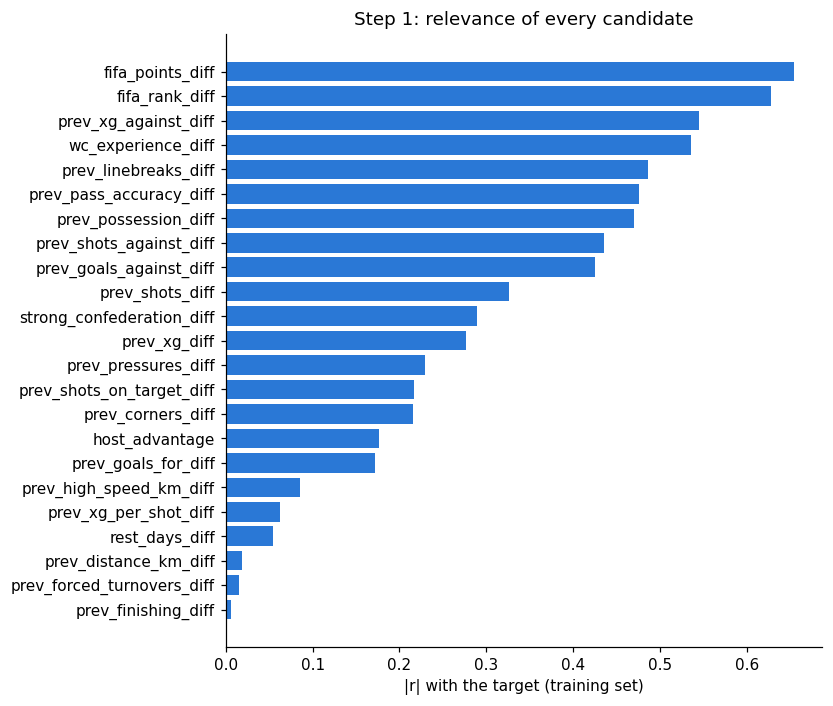

In [4]:
relevance = train[CANDIDATES].corrwith(train[TARGET]).rename("r with target (train)").to_frame()
relevance["|r|"] = relevance.iloc[:, 0].abs()
relevance = relevance.sort_values("|r|", ascending=False).round(3)
display(relevance)

fig, ax = plt.subplots(figsize=(7, 0.28 * len(relevance) + 0.8))
ax.barh(relevance.index[::-1], relevance["|r|"][::-1], color=BLUE)
ax.set(xlabel="|r| with the target (training set)", title="Step 1: relevance of every candidate")
fig.savefig(OUT / "figures" / "selection_relevance.png", bbox_inches="tight")
plt.show()

**EDA check of the strongest candidates.** Scatter plots of the 12 most relevant candidates against the target
(training set) confirm whether each relationship is roughly linear, or driven by a few extreme points.

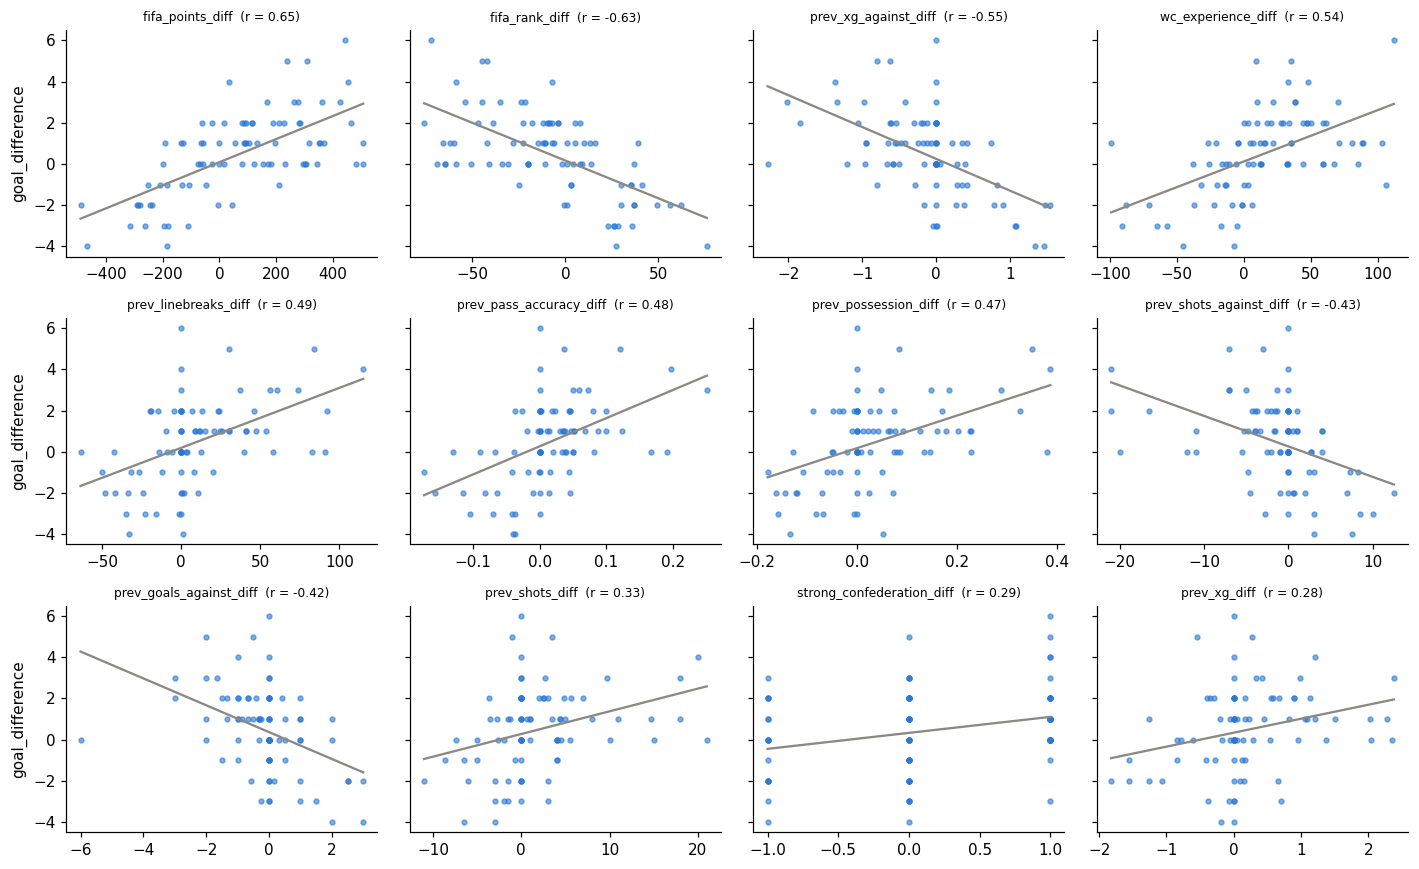

In [5]:
top12 = list(relevance.index[:12])
fig, axes = plt.subplots(3, 4, figsize=(13, 8), sharey=True)
for ax, col in zip(axes.ravel(), top12):
    ax.scatter(train[col], train[TARGET], s=10, alpha=0.6, color=BLUE)
    slope, intercept = np.polyfit(train[col], train[TARGET], 1)
    xs = np.linspace(train[col].min(), train[col].max(), 50)
    ax.plot(xs, intercept + slope * xs, color=GREY, linewidth=1.5)
    ax.set_title(f"{col}  (r = {relevance.loc[col].iloc[0]:.2f})", fontsize=8)
for ax in axes[:, 0]:
    ax.set_ylabel(TARGET)
fig.tight_layout()
fig.savefig(OUT / "figures" / "eda_top_candidates.png", bbox_inches="tight")
plt.show()

## 5. Variable selection, steps 2 and 3: redundancy and collinearity
* **Step 2, redundancy.** Go down the ranked list. Accept a candidate only if its |r| with every variable already
  accepted is below 0.8; otherwise it is a near duplicate of a stronger variable and is skipped. Stop at 8.
* **Step 3, collinearity.** Compute the variance inflation factor (VIF) of the 8. If any VIF is 5 or more, remove the
  least relevant of the variables with VIF of 5 or more, then repeat. The thresholds 0.8 and 5 are common rules of thumb.

* **Shared variable rule.** The unit allows at most 4 explanatory variables to be shared between Models 2.1 and 2.2.
  The lecturer counts a difference (team1 minus team2) and a team level version as distinct variables, but this
  project applies a **stricter** rule: two variables built from the same underlying statistic (for example
  `fifa_points_diff` and `team_fifa_points`) count as shared. Model 2.1 is selected first; Model 2.2 then skips any
  candidate that would take the shared count above 4.

The procedure is a fixed rule, so the same data always give the same 8 variables.

In [6]:
R_MAX, VIF_MAX, K, MAX_SHARED = 0.8, 5, 8, 4


def base_stat(variable):
    """Underlying statistic of a variable, e.g. fifa_points_diff, team_fifa_points -> fifa_points."""
    v = variable.replace("host_advantage", "is_host")
    for part in ("team_", "opponent_"):
        v = v.replace(part, "", 1) if v.startswith(part) else v
    return v[:-5] if v.endswith("_diff") else v


# Underlying statistics already used by the other model (read from Part 3's saved dataset, if it exists).
other_file = PROCESSED / "wc2026_goal_difference.csv"
OTHER_BASES = set()
if TARGET == "goals_scored":
    other_vars = list(pd.read_csv(other_file).columns[8:])        # the 8 variables chosen in Part 3
    OTHER_BASES = {base_stat(v) for v in other_vars}
    print("Underlying statistics used by Model 2.1:", sorted(OTHER_BASES))


def vif_table(frame, cols):
    X = sm.add_constant(frame[cols])
    return pd.Series([variance_inflation_factor(X.values, i + 1) for i in range(len(cols))], index=cols)


def select_variables(frame, candidates, target, k=K, log=None):
    """Relevance ranking, then redundancy filter (|r| < R_MAX), then VIF check (< VIF_MAX)."""
    ranked = frame[candidates].corrwith(frame[target]).abs().sort_values(ascending=False)
    pool = [c for c in ranked.index if frame[c].std() > 0]
    while True:
        chosen, shared = [], 0
        for c in pool:
            if base_stat(c) in OTHER_BASES and shared >= MAX_SHARED:
                if log is not None:
                    log[c] = "skipped: would exceed 4 variables shared with Model 2.1"
                continue
            clash = [a for a in chosen if abs(frame[c].corr(frame[a])) >= R_MAX]
            if clash:
                if log is not None:
                    log[c] = f"skipped: near duplicate of {clash[0]} (r = {frame[c].corr(frame[clash[0]]):.2f})"
                continue
            chosen.append(c)
            shared += base_stat(c) in OTHER_BASES
            if len(chosen) == k:
                break
        vifs = vif_table(frame, chosen)
        if vifs.max() < VIF_MAX:
            return chosen
        # Among the collinear variables (VIF >= 5), drop the LEAST relevant one, keeping the stronger signal.
        collinear = vifs[vifs >= VIF_MAX].index
        drop = min(collinear, key=lambda c: ranked[c])
        if log is not None:
            log[drop] = f"removed: collinear (VIF {vifs[drop]:.1f}) and least relevant of the collinear group"
        pool.remove(drop)


decisions = {}
SELECTED = select_variables(train, CANDIDATES, TARGET, log=decisions)
summary = relevance.copy()
summary["decision"] = [("SELECTED" if c in SELECTED else decisions.get(c, "not needed: 8 already selected"))
                       for c in summary.index]
summary.to_csv(OUT / "tables" / "variable_selection.csv")
display(summary)
print("Selected variables:", SELECTED)
if OTHER_BASES:
    print("Shared with Model 2.1 (same underlying statistic):", [v for v in SELECTED if base_stat(v) in OTHER_BASES])

,r with target (train),|r|,decision
fifa_points_diff,0.654,0.654,SELECTED
fifa_rank_diff,-0.627,0.627,skipped: near duplicate of fifa_points_diff (r...
prev_xg_against_diff,-0.545,0.545,removed: collinear (VIF 7.6) and least relevan...
wc_experience_diff,0.536,0.536,SELECTED
prev_linebreaks_diff,0.486,0.486,SELECTED
prev_pass_accuracy_diff,0.476,0.476,skipped: near duplicate of prev_linebreaks_dif...
prev_possession_diff,0.470,0.470,skipped: near duplicate of prev_linebreaks_dif...
prev_shots_against_diff,-0.435,0.435,SELECTED
prev_goals_against_diff,-0.425,0.425,SELECTED
prev_shots_diff,0.326,0.326,SELECTED


Selected variables: ['fifa_points_diff', 'wc_experience_diff', 'prev_linebreaks_diff', 'prev_shots_against_diff', 'prev_goals_against_diff', 'prev_shots_diff', 'strong_confederation_diff', 'prev_xg_diff']


In [7]:
vif_final = vif_table(train, SELECTED).round(2).rename("VIF (training set)").to_frame()
vif_final.to_csv(OUT / "tables" / "vif_selected.csv")
display(vif_final)
print("Largest VIF:", vif_final.iloc[:, 0].max(), "(below the threshold of 5)")

,VIF (training set)
fifa_points_diff,3.10
wc_experience_diff,3.05
prev_linebreaks_diff,2.80
prev_shots_against_diff,2.76
prev_goals_against_diff,1.38
prev_shots_diff,3.32
strong_confederation_diff,1.40
prev_xg_diff,3.08


Largest VIF: 3.32 (below the threshold of 5)


## 6. Save the final dataset with exactly 8 explanatory variables

In [8]:
final = df[ID_COLS + [TARGET] + SELECTED]
assert len(SELECTED) == 8 and len(final) == 104
final.to_csv(PROCESSED / "wc2026_goal_difference.csv", index=False)
print("Saved", PROCESSED / "wc2026_goal_difference.csv", final.shape)
display(final.head())

Saved /home/claude/A3/data/processed/wc2026_goal_difference.csv (104, 16)


,match_number,date,stage,team1,team2,team1_goals,team2_goals,goal_difference,fifa_points_diff,wc_experience_diff,prev_linebreaks_diff,prev_shots_against_diff,prev_goals_against_diff,prev_shots_diff,strong_confederation_diff,prev_xg_diff
0,1,2026-06-11,First Stage,Mexico,South Africa,2,0,2,259,51,0.0,0.0,0.0,0.0,0,0.0
1,2,2026-06-12,First Stage,Korea Republic,Czechia,2,1,1,86,35,0.0,0.0,0.0,0.0,-1,0.0
2,3,2026-06-12,First Stage,Canada,Bosnia and Herzegovina,1,1,0,172,3,0.0,0.0,0.0,0.0,-1,0.0
3,4,2026-06-13,First Stage,USA,Paraguay,4,1,3,166,10,0.0,0.0,0.0,0.0,-1,0.0
4,7,2026-06-13,First Stage,Brazil,Morocco,1,1,0,11,91,0.0,0.0,0.0,0.0,1,0.0


## 7. Descriptive statistics of the selected variables (all rows)

In [9]:
X_all, y_all = df[SELECTED], df[TARGET]
describe = df[[TARGET] + SELECTED].describe().T.round(3)
describe.to_csv(OUT / "tables" / "descriptive_statistics.csv")
display(describe)

,count,mean,std,min,25%,50%,75%,max
goal_difference,104.0,0.481,2.024,-4.000,-1.000,0.0,2.000,6.00
fifa_points_diff,104.0,55.212,231.551,-489.000,-128.000,68.0,232.750,506.00
wc_experience_diff,104.0,12.692,43.698,-99.000,-14.000,9.5,38.000,112.00
prev_linebreaks_diff,104.0,8.198,33.453,-76.750,-6.125,0.0,23.700,115.00
prev_shots_against_diff,104.0,-1.216,6.087,-21.000,-3.083,0.0,1.000,13.25
prev_goals_against_diff,104.0,-0.176,1.271,-6.000,-0.688,0.0,0.208,3.00
prev_shots_diff,104.0,1.397,6.194,-11.000,-1.625,0.0,4.000,21.00
strong_confederation_diff,104.0,0.154,0.747,-1.000,0.000,0.0,1.000,1.00
prev_xg_diff,104.0,0.129,0.804,-1.822,-0.213,0.0,0.538,2.38


## 8. Distribution of the target

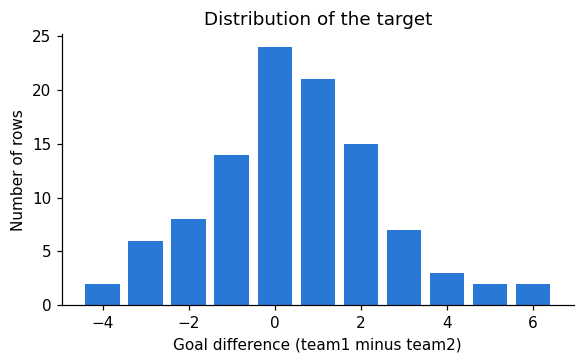

Mean: 0.481 | median: 0.0 | SD: 2.024 | skewness: 0.254


In [10]:
counts = y_all.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(counts.index, counts.values, color=BLUE, width=0.8)
ax.set(xlabel="Goal difference (team1 minus team2)", ylabel="Number of rows", title="Distribution of the target")
fig.savefig(OUT / "figures" / "target_distribution.png", bbox_inches="tight")
plt.show()
print("Mean:", round(y_all.mean(), 3), "| median:", y_all.median(), "| SD:", round(y_all.std(), 3),
      "| skewness:", round(stats.skew(y_all), 3))

## 9. Relationship between each selected variable and the target
Scatter plots with a straight trend line show whether a linear relationship is reasonable.

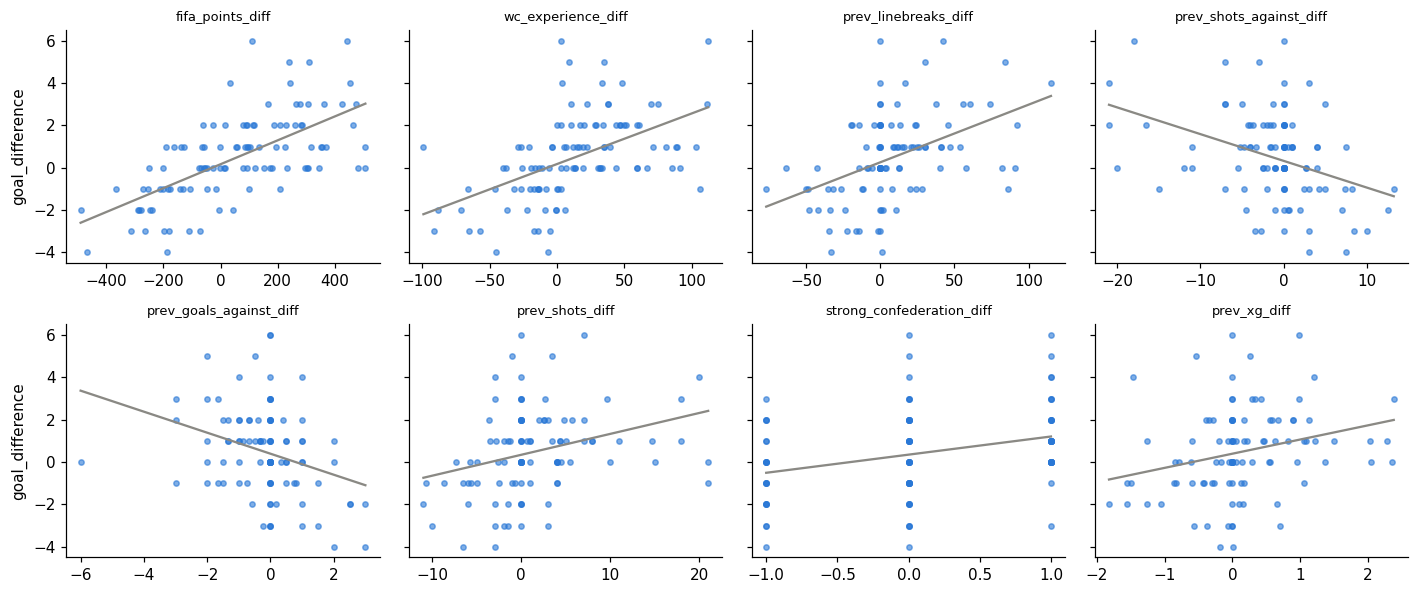

In [11]:
fig, axes = plt.subplots(2, 4, figsize=(13, 5.5), sharey=True)
for ax, col in zip(axes.ravel(), SELECTED):
    ax.scatter(df[col], y_all, s=12, alpha=0.6, color=BLUE)
    slope, intercept = np.polyfit(df[col], y_all, 1)
    xs = np.linspace(df[col].min(), df[col].max(), 50)
    ax.plot(xs, intercept + slope * xs, color=GREY, linewidth=1.5)
    ax.set_title(col, fontsize=8.5)
for ax in axes[:, 0]:
    ax.set_ylabel(TARGET)
fig.tight_layout()
fig.savefig(OUT / "figures" / "scatter_selected_variables.png", bbox_inches="tight")
plt.show()

## 10. Correlation between the selected variables

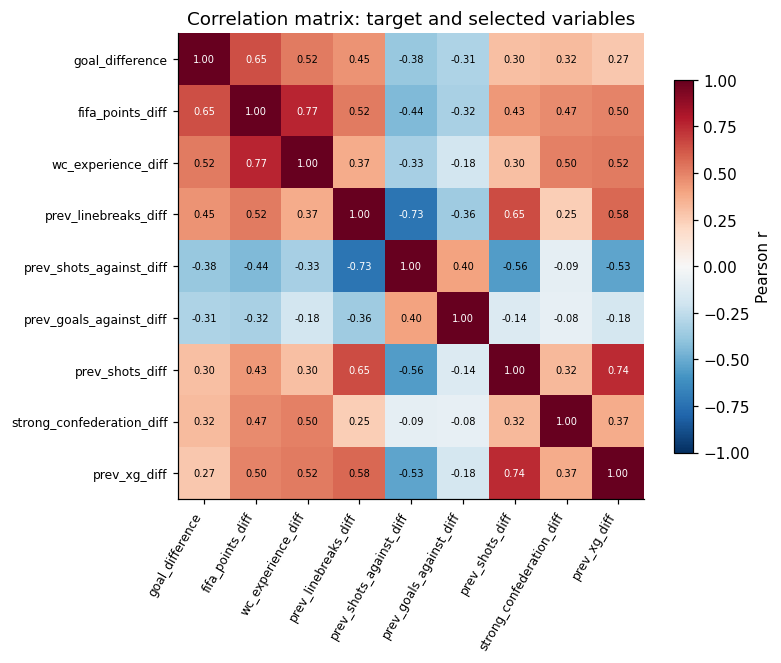

In [12]:
corr = df[[TARGET] + SELECTED].corr()
fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(corr)), corr.columns, fontsize=8)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6.5,
                color="white" if abs(corr.iloc[i, j]) > 0.6 else "black")
fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson r")
ax.set_title("Correlation matrix: target and selected variables")
fig.savefig(OUT / "figures" / "correlation_matrix.png", bbox_inches="tight")
plt.show()

## 11. Baseline model
The baseline predicts the **mean of the training target** for every test row. A useful model must beat it.

In [13]:
X_train, y_train = train[SELECTED], train[TARGET]
X_test, y_test = test[SELECTED], test[TARGET]
baseline_pred = np.full(len(y_test), y_train.mean())
print("Baseline prediction for every test row:", round(y_train.mean(), 3))

Baseline prediction for every test row: 0.47


## 12. Fit the linear regression model on the training set

In [14]:
model = LinearRegression().fit(X_train, y_train)
print("Intercept:", round(model.intercept_, 4))
display(pd.DataFrame({"variable": SELECTED, "coefficient": model.coef_}).round(4))

Intercept: -0.0212


,variable,coefficient
0,fifa_points_diff,0.0032
1,wc_experience_diff,0.0122
2,prev_linebreaks_diff,0.0123
3,prev_shots_against_diff,0.0177
4,prev_goals_against_diff,-0.3291
5,prev_shots_diff,0.0723
6,strong_confederation_diff,-0.0727
7,prev_xg_diff,-0.8029


## 13. Evaluate on the held out test set
* **MAE**: average absolute error, in goals. **MSE**: average squared error. **RMSE**: its square root, in goals.
* **NRMSE**: RMSE divided by the range of the test target. **R²**: share of variance explained.
* **Adjusted R²**: R² penalised for the 8 variables. On a small test set it is very sensitive, so the full sample
  adjusted R² (Block 15) and cross validation (Block 18) are the more reliable summaries.

In [15]:
y_pred = model.predict(X_test)


def evaluate(actual, predicted, p=len(SELECTED)):
    mse = mean_squared_error(actual, predicted)
    r2 = r2_score(actual, predicted)
    n = len(actual)
    return {"MAE": mean_absolute_error(actual, predicted), "MSE": mse, "RMSE": np.sqrt(mse),
            "NRMSE": np.sqrt(mse) / (actual.max() - actual.min()), "R2": r2,
            "Adjusted R2": 1 - (1 - r2) * (n - 1) / (n - p - 1)}


results = pd.DataFrame({"Linear regression": evaluate(y_test, y_pred),
                        "Baseline (mean)": evaluate(y_test, baseline_pred)}).round(3)
results.to_csv(OUT / "tables" / "test_set_evaluation.csv")
display(results)

,Linear regression,Baseline (mean)
MAE,1.353,1.588
MSE,3.421,4.157
RMSE,1.850,2.039
NRMSE,0.206,0.227
R2,0.177,-0.001
Adjusted R2,-0.372,-0.668


## 14. Actual vs predicted (test set)

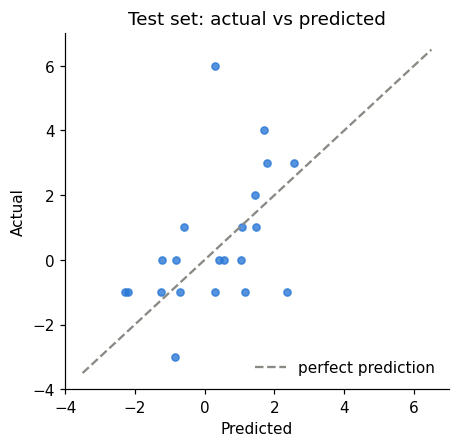

In [16]:
fig, ax = plt.subplots(figsize=(4.5, 4.2))
ax.scatter(y_pred, y_test, s=22, color=BLUE, alpha=0.8)
lims = [min(y_test.min(), y_pred.min()) - 0.5, max(y_test.max(), y_pred.max()) + 0.5]
ax.plot(lims, lims, "--", color=GREY, label="perfect prediction")
ax.set(xlabel="Predicted", ylabel="Actual", title="Test set: actual vs predicted")
ax.legend(frameon=False)
fig.savefig(OUT / "figures" / "actual_vs_predicted.png", bbox_inches="tight")
plt.show()

## 15. Inference: OLS on all rows
`statsmodels` fits the same model on all rows to estimate each coefficient with a standard error, p value and 95%
confidence interval. Each coefficient is the change in the target for a one unit increase in that variable,
**holding the other seven constant**.

In [17]:
ols = sm.OLS(y_all, sm.add_constant(X_all)).fit()
print(ols.summary())

                            OLS Regression Results                            
Dep. Variable:        goal_difference   R-squared:                       0.472
Model:                            OLS   Adj. R-squared:                  0.428
Method:                 Least Squares   F-statistic:                     10.62
Date:                Fri, 02 Oct 2026   Prob (F-statistic):           1.52e-10
Time:                        09:58:52   Log-Likelihood:                -187.19
No. Observations:                 104   AIC:                             392.4
Df Residuals:                      95   BIC:                             416.2
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                                coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------
const                 

In [18]:
ols_table = pd.DataFrame({"coefficient": ols.params, "std error": ols.bse, "t": ols.tvalues, "p value": ols.pvalues,
                          "95% CI low": ols.conf_int()[0], "95% CI high": ols.conf_int()[1]}).round(4)
ols_table.to_csv(OUT / "tables" / "ols_coefficients.csv")
significant = [v for v in SELECTED if ols.pvalues[v] < 0.05]
print("Significant at the 0.05 level:", significant if significant else "none")

Significant at the 0.05 level: ['fifa_points_diff', 'prev_xg_diff']


In [19]:
# Sensitivity check: heteroscedasticity robust (HC3) standard errors. If conclusions hold, they do not depend
# on the equal variance assumption.
robust = sm.OLS(y_all, sm.add_constant(X_all)).fit(cov_type="HC3")
compare_se = pd.DataFrame({"p value (classical)": ols.pvalues, "p value (HC3 robust)": robust.pvalues}).round(4)
display(compare_se)

,p value (classical),p value (HC3 robust)
const,0.6823,0.6798
fifa_points_diff,0.0007,0.0007
wc_experience_diff,0.2194,0.3364
prev_linebreaks_diff,0.1921,0.1658
prev_shots_against_diff,0.6533,0.7748
prev_goals_against_diff,0.3279,0.4894
prev_shots_diff,0.4961,0.5597
strong_confederation_diff,0.7232,0.7385
prev_xg_diff,0.0384,0.0885


## 16. What do the coefficients mean in goals?
Raw coefficients use different units, so each effect is shown for a **realistic change**: moving from the 25th to the
75th percentile of that variable (the interquartile range), with the other seven held constant.
Standardised coefficients (z scores) rank the variables on one scale.

In [20]:
iqr = X_all.quantile(0.75) - X_all.quantile(0.25)
effects = pd.DataFrame({"coefficient": ols.params[SELECTED], "IQR of variable": iqr,
                        "effect of an IQR change (goals)": ols.params[SELECTED] * iqr,
                        "95% CI low (goals)": ols.conf_int().loc[SELECTED, 0] * iqr,
                        "95% CI high (goals)": ols.conf_int().loc[SELECTED, 1] * iqr,
                        "p value": ols.pvalues[SELECTED]}).round(3)
effects = effects.reindex(effects["effect of an IQR change (goals)"].abs().sort_values(ascending=False).index)
effects.to_csv(OUT / "tables" / "practical_effects.csv")
display(effects)

,coefficient,IQR of variable,effect of an IQR change (goals),95% CI low (goals),95% CI high (goals),p value
fifa_points_diff,0.004,360.750,1.466,0.639,2.292,0.001
prev_xg_diff,-0.675,0.752,-0.507,-0.987,-0.028,0.038
wc_experience_diff,0.007,52.000,0.390,-0.236,1.016,0.219
prev_linebreaks_diff,0.010,29.825,0.301,-0.154,0.755,0.192
prev_shots_diff,0.029,5.625,0.165,-0.314,0.644,0.496
prev_goals_against_diff,-0.134,0.896,-0.120,-0.361,0.122,0.328
strong_confederation_diff,0.088,1.000,0.088,-0.406,0.583,0.723
prev_shots_against_diff,-0.018,4.083,-0.073,-0.393,0.248,0.653


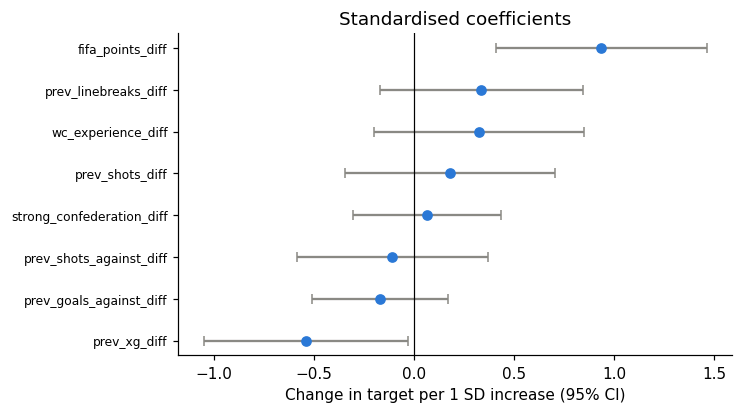

In [21]:
Z = StandardScaler().fit_transform(X_all)
std_ols = sm.OLS(y_all, sm.add_constant(Z)).fit()
std_coef = pd.Series(np.asarray(std_ols.params)[1:], index=SELECTED)       # drop the intercept
std_ci = pd.DataFrame(np.asarray(std_ols.conf_int())[1:], index=SELECTED)
order = std_coef.sort_values().index
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.errorbar(std_coef[order], range(len(order)), xerr=[std_coef[order] - std_ci.loc[order, 0],
            std_ci.loc[order, 1] - std_coef[order]], fmt="o", color=BLUE, ecolor=GREY, capsize=3)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_yticks(range(len(order)), order, fontsize=8)
ax.set(xlabel="Change in target per 1 SD increase (95% CI)", title="Standardised coefficients")
fig.savefig(OUT / "figures" / "standardised_coefficients.png", bbox_inches="tight")
plt.show()

## 17. Check the regression assumptions
| Assumption | Check | Reading |
|---|---|---|
| Linearity | residuals vs fitted plot; Rainbow test | p < 0.05 suggests a non linear pattern |
| Equal spread of residuals | Breusch-Pagan test | p < 0.05 suggests unequal spread |
| Normal residuals | Q-Q plot; Jarque-Bera test | p < 0.05 suggests non normal residuals |
| Independent residuals | Durbin-Watson statistic | values near 2 suggest no autocorrelation |
| No severe collinearity | VIF (Block 5) | all below 5 |

,check,value,type,assumption met?
0,Rainbow (linearity),0.5761,p value,yes
1,Breusch-Pagan (equal spread),0.2596,p value,yes
2,Jarque-Bera (normality),0.0629,p value,yes
3,Durbin-Watson (independence),1.9018,statistic,yes


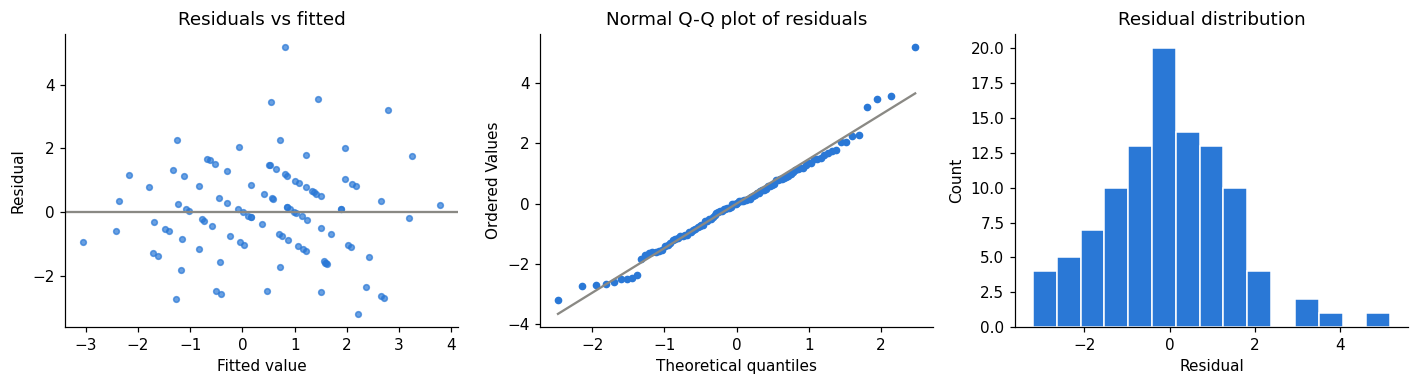

In [22]:
residuals, fitted = ols.resid, ols.fittedvalues
tests = pd.DataFrame({
    "check": ["Rainbow (linearity)", "Breusch-Pagan (equal spread)", "Jarque-Bera (normality)",
              "Durbin-Watson (independence)"],
    "value": [linear_rainbow(ols)[1], het_breuschpagan(residuals, sm.add_constant(X_all))[1],
              jarque_bera(residuals)[1], durbin_watson(residuals)],
    "type": ["p value", "p value", "p value", "statistic"]}).round(4)
tests["assumption met?"] = ["yes" if v >= 0.05 else "no" for v in tests["value"][:3]] + \
                           ["yes" if 1.5 <= tests["value"].iloc[3] <= 2.5 else "no"]
tests.to_csv(OUT / "tables" / "assumption_tests.csv", index=False)
display(tests)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
axes[0].scatter(fitted, residuals, s=14, color=BLUE, alpha=0.7)
axes[0].axhline(0, color=GREY)
axes[0].set(xlabel="Fitted value", ylabel="Residual", title="Residuals vs fitted")
stats.probplot(residuals, dist="norm", plot=axes[1])
axes[1].get_lines()[0].set(color=BLUE, markersize=4)
axes[1].get_lines()[1].set(color=GREY)
axes[1].set_title("Normal Q-Q plot of residuals")
axes[2].hist(residuals, bins=15, color=BLUE, edgecolor="white")
axes[2].set(xlabel="Residual", ylabel="Count", title="Residual distribution")
fig.tight_layout()
fig.savefig(OUT / "figures" / "residual_diagnostics.png", bbox_inches="tight")
plt.show()

## 18. Exploring viable alternatives
Several reasonable models are compared on **the same 50 cross validation folds**, so the comparison is fair:

* **Baseline**: the training mean.
* **Strength only**: pre tournament variables only (no tournament form).
* **Form only**: tournament form variables only (no pre tournament strength).
* **Judgement 8**: eight variables chosen by football reasoning alone, without the selection procedure.
* **Selected 8**: the final model.

In [23]:
def make_folds(repeats=10):
    """50 train/test index pairs: 5 fold cross validation repeated 10 times with different shuffles."""
    folds = []
    for r in range(repeats):
        folds += list(KFold(n_splits=5, shuffle=True, random_state=42 + r).split(df))
    return folds


FOLDS = make_folds()


def fit_linear(Xtr, ytr):
    m = LinearRegression().fit(Xtr, ytr)
    return m.predict


def fit_mean(Xtr, ytr):
    return lambda Xte: np.full(len(Xte), ytr.mean())


alternatives = {
    "Baseline (mean)": (SELECTED, fit_mean),
    "Strength only": (['fifa_points_diff', 'wc_experience_diff', 'host_advantage'], fit_linear),
    "Form only": (['prev_xg_diff', 'prev_xg_against_diff', 'prev_goals_for_diff', 'prev_goals_against_diff'], fit_linear),
    "Judgement 8 (no procedure)": (['fifa_points_diff', 'host_advantage', 'wc_experience_diff', 'prev_xg_diff', 'prev_xg_against_diff', 'prev_shots_on_target_diff', 'prev_possession_diff', 'rest_days_diff'], fit_linear),
    "Selected 8 (final model)": (SELECTED, fit_linear),
}


rows = {}
for name, (cols, fitter) in alternatives.items():
    errs = []
    for a, b in FOLDS:
        predict = fitter(df.iloc[a][cols], y_all.iloc[a])
        p = predict(df.iloc[b][cols])
        errs.append([mean_absolute_error(y_all.iloc[b], p), np.sqrt(mean_squared_error(y_all.iloc[b], p)),
                     r2_score(y_all.iloc[b], p)])
    errs = np.array(errs)
    rows[name] = {"variables": 0 if name.startswith("Baseline") else len(cols), "CV MAE": errs[:, 0].mean(), "CV RMSE": errs[:, 1].mean(),
                  "RMSE SD": errs[:, 1].std(), "CV R2": errs[:, 2].mean()}
comparison = pd.DataFrame(rows).T
comparison[["CV MAE", "CV RMSE", "RMSE SD", "CV R2"]] = comparison[["CV MAE", "CV RMSE", "RMSE SD", "CV R2"]].astype(float).round(3)
comparison.to_csv(OUT / "tables" / "alternative_models.csv")
display(comparison)

,variables,CV MAE,CV RMSE,RMSE SD,CV R2
Baseline (mean),0.0,1.585,2.009,0.304,-0.052
Strength only,3.0,1.256,1.587,0.257,0.322
Form only,4.0,1.441,1.877,0.251,0.054
Judgement 8 (no procedure),8.0,1.281,1.617,0.264,0.290
Selected 8 (final model),8.0,1.273,1.641,0.312,0.271


## 19. Optimising the linear model (feature engineering and data transformation)
Starting from plain OLS on the selected 8, three improvements are tested **one step at a time** on the same 50 folds.
Each step is kept only if it lowers the cross validated RMSE.

1. **Reliability weighting (feature engineering).** A form average from 1 earlier match is far noisier than one
   from 6, so each form variable is multiplied by n / (n + 2), where n is the number of earlier matches. Weak
   evidence is shrunk towards 0 ("average"). Both teams in a match have always played the same number of games.
2. **Yeo-Johnson power transformation (data transformation).** It makes each skewed variable closer to a normal
   shape and standardises it. Unlike a log transform it also works for zero and negative values.
3. **Ridge regularisation.** Still a linear regression, but it shrinks unstable coefficients. Its strength (alpha)
   is tuned by cross validation **inside each training fold**, so the test fold never influences it.

Every transformation is learned from the training fold only (scikit-learn pipelines), so there is no leakage.

In [24]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PowerTransformer
from sklearn.linear_model import RidgeCV

# n = World Cup 2026 matches each team had played before this match (equal for both teams in a match).
team_col = "team1" if TARGET == "goal_difference" else "team"
order = df.sort_values(["date", "match_number"])
if TARGET == "goal_difference":
    long = pd.concat([order[["match_number", "date", "team1"]].rename(columns={"team1": "t"}),
                      order[["match_number", "date", "team2"]].rename(columns={"team2": "t"})]).sort_values(["date", "match_number"])
    long["n"] = long.groupby("t").cumcount()
    n_prev = df["match_number"].map(long.groupby("match_number")["n"].min())
else:
    n_prev = df["match_number"].map(order.assign(n=order.groupby("team").cumcount()).groupby("match_number")["n"].min())
FORM_VARS = [c for c in SELECTED if "prev_" in c]
weighted = X_all.copy()
weighted[FORM_VARS] = weighted[FORM_VARS].mul(n_prev / (n_prev + 2), axis=0)

ALPHAS = np.logspace(-2, 3, 30)
steps = {
    "Step 0: OLS on the selected 8": (X_all, lambda: LinearRegression()),
    "Step 1: + reliability weighting of form": (weighted, lambda: LinearRegression()),
    "Step 2: + Yeo-Johnson transformation": (weighted, lambda: make_pipeline(PowerTransformer(), LinearRegression())),
    "Step 2 alt: Yeo-Johnson without weighting": (X_all, lambda: make_pipeline(PowerTransformer(), LinearRegression())),
    "Step 3: Yeo-Johnson + Ridge (alpha tuned)": (X_all, lambda: make_pipeline(PowerTransformer(), RidgeCV(alphas=ALPHAS))),
    "Step 3 alt: weighting + Yeo-Johnson + Ridge": (weighted, lambda: make_pipeline(PowerTransformer(), RidgeCV(alphas=ALPHAS))),
}
step_rmse = {}
for name, (Xd, make_model) in steps.items():
    step_rmse[name] = np.array([np.sqrt(mean_squared_error(y_all.iloc[b], make_model().fit(Xd.iloc[a], y_all.iloc[a])
                                                            .predict(Xd.iloc[b]))) for a, b in FOLDS])

J = len(FOLDS)
ratio = np.mean([len(b) / len(a) for a, b in FOLDS])          # test size / training size


def corrected_test(diff):
    """Nadeau and Bengio (2003) corrected resampled t test for a paired difference over J overlapping folds."""
    se = np.sqrt((1 / J + ratio) * diff.var(ddof=1))
    t = diff.mean() / se if se > 0 else 0.0
    return se, 2 * stats.t.sf(abs(t), df=J - 1)


base = step_rmse["Step 0: OLS on the selected 8"]
opt_table = pd.DataFrame({name: {"CV RMSE": v.mean(), "change vs step 0 (%)": 100 * (v.mean() - base.mean()) / base.mean(),
                                 "p value vs step 0 (corrected)": corrected_test(v - base)[1] if v is not base else 1.0,
                                 "folds better than step 0": int((v < base).sum())}
                          for name, v in step_rmse.items()}).T.astype(float).round(4)
opt_table.to_csv(OUT / "tables" / "optimisation_steps.csv")
display(opt_table)
OPT_NAME = opt_table["CV RMSE"].idxmin()
print("Best optimised configuration:", OPT_NAME)

,CV RMSE,change vs step 0 (%),p value vs step 0 (corrected),folds better than step 0
Step 0: OLS on the selected 8,1.6413,0.0000,1.0000,0.0
Step 1: + reliability weighting of form,1.6215,-1.2032,0.5286,30.0
Step 2: + Yeo-Johnson transformation,1.6167,-1.4949,0.5048,33.0
Step 2 alt: Yeo-Johnson without weighting,1.6108,-1.8571,0.1976,39.0
Step 3: Yeo-Johnson + Ridge (alpha tuned),1.5857,-3.3878,0.2591,37.0
Step 3 alt: weighting + Yeo-Johnson + Ridge,1.5931,-2.9369,0.3851,33.0


Best optimised configuration: Step 3: Yeo-Johnson + Ridge (alpha tuned)


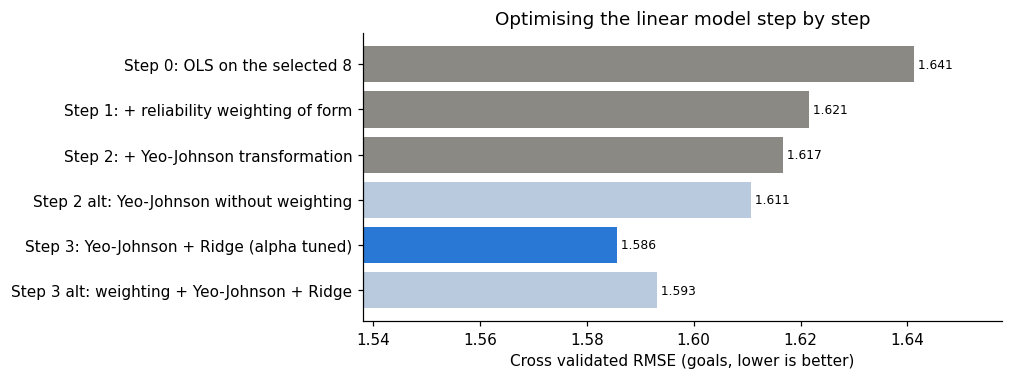

,OLS (step 0),Optimised,Baseline (mean)
MAE,1.353,1.365,1.588
MSE,3.421,3.202,4.157
RMSE,1.850,1.789,2.039
NRMSE,0.206,0.199,0.227
R2,0.177,0.229,-0.001
Adjusted R2,-0.372,-0.285,-0.668


Ridge alpha chosen on the training set: 12.69


In [25]:
# Visual summary of the optimisation path.
fig, ax = plt.subplots(figsize=(7.5, 3.4))
names = list(opt_table.index)
colors = [BLUE if n == OPT_NAME else ("#b9c9de" if "alt" in n else GREY) for n in names]
ax.barh(names[::-1], opt_table["CV RMSE"][::-1], color=colors[::-1])
ax.set_xlim(opt_table["CV RMSE"].min() * 0.97, opt_table["CV RMSE"].max() * 1.01)
for i, (n, v) in enumerate(zip(names[::-1], opt_table["CV RMSE"][::-1])):
    ax.text(v, i, f" {v:.3f}", va="center", fontsize=8)
ax.set(xlabel="Cross validated RMSE (goals, lower is better)", title="Optimising the linear model step by step")
fig.savefig(OUT / "figures" / "optimisation_steps.png", bbox_inches="tight")
plt.show()

# The optimised model, fitted on the training set and checked on the untouched test set.
opt_X = weighted if "weighting" in OPT_NAME else X_all
opt_model = steps[OPT_NAME][1]().fit(opt_X.iloc[train_idx], y_all.iloc[train_idx])
opt_pred = opt_model.predict(opt_X.iloc[test_idx])
test_compare = pd.DataFrame({"OLS (step 0)": evaluate(y_test, y_pred), "Optimised": evaluate(y_test, opt_pred),
                             "Baseline (mean)": evaluate(y_test, baseline_pred)}).round(3)
test_compare.to_csv(OUT / "tables" / "test_set_optimised.csv")
display(test_compare)
if hasattr(opt_model[-1], "alpha_"):
    print("Ridge alpha chosen on the training set:", round(opt_model[-1].alpha_, 3))

## 20. Is the selection procedure itself reliable? Nested cross validation
In Blocks 18 and 19 the selected 8 were chosen on a training set that overlaps the folds, which can flatter them slightly.
Here the **whole selection procedure is rerun inside every training fold**, so each test fold is never seen by any
decision. This gives an honest estimate of how the method performs on new matches, and shows how often each
variable is selected.

In [26]:
nested, picks = [], pd.Series(0, index=CANDIDATES)
for a, b in FOLDS:
    cols = select_variables(df.iloc[a], CANDIDATES, TARGET)
    picks[cols] += 1
    m = LinearRegression().fit(df.iloc[a][cols], y_all.iloc[a])
    p, base = m.predict(df.iloc[b][cols]), np.full(len(b), y_all.iloc[a].mean())
    nested.append([np.sqrt(mean_squared_error(y_all.iloc[b], p)), np.sqrt(mean_squared_error(y_all.iloc[b], base)),
                   r2_score(y_all.iloc[b], p)])
nested = np.array(nested)
print(f"Nested CV RMSE: model {nested[:, 0].mean():.3f} (SD {nested[:, 0].std():.3f}) "
      f"vs baseline {nested[:, 1].mean():.3f}")
print(f"Nested CV R2: {nested[:, 2].mean():.3f} | model beat the baseline in {(nested[:, 0] < nested[:, 1]).sum()} of {len(FOLDS)} folds")
stability = (picks / len(FOLDS)).sort_values(ascending=False).rename("share of folds selected").to_frame()
stability["in final 8"] = ["yes" if c in SELECTED else "" for c in stability.index]
stability.to_csv(OUT / "tables" / "selection_stability.csv")
display(stability[stability.iloc[:, 0] > 0].round(2))

Nested CV RMSE: model 1.633 (SD 0.280) vs baseline 2.009
Nested CV R2: 0.276 | model beat the baseline in 44 of 50 folds


,share of folds selected,in final 8
fifa_points_diff,1.00,yes
wc_experience_diff,0.98,yes
strong_confederation_diff,0.94,yes
prev_xg_against_diff,0.94,
prev_shots_diff,0.92,yes
prev_goals_against_diff,0.88,yes
prev_linebreaks_diff,0.84,yes
prev_xg_diff,0.60,yes
prev_corners_diff,0.32,
prev_pass_accuracy_diff,0.20,


## 21. Competing algorithms and recommendation
Linear regression is one of many regression algorithms. The optimised linear model from Block 19 is compared, on the
**same 8 selected variables and the same 50 folds**, with plain OLS, regularised linear models (Ridge, Lasso), a distance based model (k nearest neighbours), tree
based models (decision tree, random forest, gradient boosting) and a kernel model (support vector regression).
Each uses fixed, commonly used settings; models sensitive to units are standardised inside the fold. Settings are
not tuned, so every model gets equal treatment.

The recommendation favours the simplest model unless another one is reliably better. Repeated cross validation
folds overlap, so a naive standard error would be far too small. The **corrected resampled t test**
(Nadeau and Bengio, 2003) inflates the variance of the paired fold by fold RMSE difference to allow for this.

,CV RMSE,RMSE SD,difference vs final model,corrected SE,p value (corrected),folds where the final model is better
Optimised linear model (Block 19),1.586,0.283,0.000,0.000,1.000,0.0
k nearest neighbours (k = 10),1.603,0.267,0.018,0.055,0.750,32.0
Lasso (alpha = 0.05),1.607,0.278,0.021,0.032,0.505,31.0
Ridge (alpha = 1),1.633,0.307,0.047,0.044,0.291,37.0
Random forest (300 trees),1.638,0.266,0.052,0.055,0.345,34.0
Linear regression (OLS),1.641,0.312,0.056,0.049,0.259,37.0
Support vector regression (RBF),1.665,0.283,0.079,0.084,0.350,35.0
Gradient boosting,1.756,0.272,0.170,0.085,0.051,43.0
Decision tree (depth 3),1.874,0.316,0.289,0.133,0.035,44.0


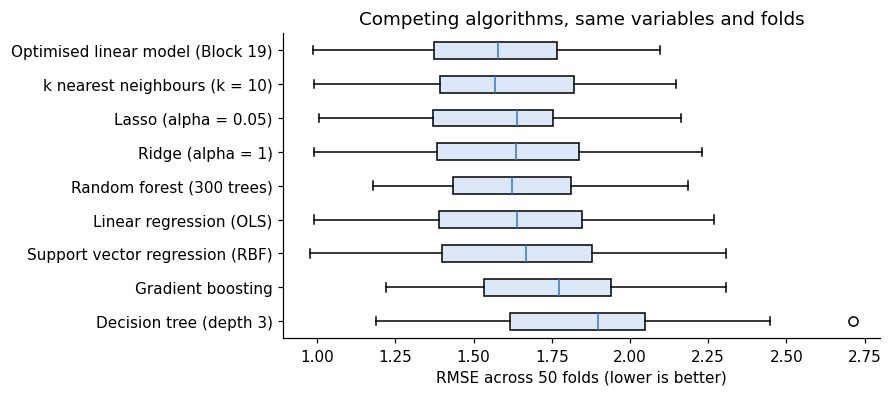

In [27]:
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR

algorithms = {
    "Linear regression (OLS)": lambda: LinearRegression(),
    "Ridge (alpha = 1)": lambda: make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Lasso (alpha = 0.05)": lambda: make_pipeline(StandardScaler(), Lasso(alpha=0.05)),
    "k nearest neighbours (k = 10)": lambda: make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=10)),
    "Decision tree (depth 3)": lambda: DecisionTreeRegressor(max_depth=3, random_state=42),
    "Random forest (300 trees)": lambda: RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=42),
    "Gradient boosting": lambda: GradientBoostingRegressor(n_estimators=150, max_depth=2, learning_rate=0.05, random_state=42),
    "Support vector regression (RBF)": lambda: make_pipeline(StandardScaler(), SVR(C=1.0)),
}
FINAL = "Optimised linear model (Block 19)"
fold_rmse = {FINAL: step_rmse[OPT_NAME]}                          # same 50 folds, computed in Block 19
for name, make_model in algorithms.items():
    errs = []
    for a, b in FOLDS:
        m = make_model().fit(df.iloc[a][SELECTED], y_all.iloc[a])
        errs.append(np.sqrt(mean_squared_error(y_all.iloc[b], m.predict(df.iloc[b][SELECTED]))))
    fold_rmse[name] = np.array(errs)

lin = fold_rmse[FINAL]                                            # the reference every algorithm is compared with
rows = {}
for k, v in fold_rmse.items():
    d = v - lin                                                  # negative = better than the optimised linear model
    se, p = corrected_test(d) if k != FINAL else (0.0, 1.0)
    rows[k] = {"CV RMSE": v.mean(), "RMSE SD": v.std(), "difference vs final model": d.mean(),
               "corrected SE": se, "p value (corrected)": p, "folds where the final model is better": int((lin < v).sum())}
algo_table = pd.DataFrame(rows).T.sort_values("CV RMSE").astype(float).round(3)
algo_table.to_csv(OUT / "tables" / "competing_algorithms.csv")
display(algo_table)

fig, ax = plt.subplots(figsize=(7, 3.6))
order = algo_table.index[::-1]
ax.boxplot([fold_rmse[k] for k in order], vert=False, tick_labels=order, patch_artist=True,
           boxprops={"facecolor": "#dce8f7"}, medianprops={"color": BLUE})
ax.set(xlabel="RMSE across 50 folds (lower is better)", title="Competing algorithms, same variables and folds")
fig.savefig(OUT / "figures" / "competing_algorithms.png", bbox_inches="tight")
plt.show()

In [28]:
best = algo_table.index[0]
if best == FINAL:
    runner = algo_table.index[1]
    recommendation = (f"The optimised linear model has the lowest cross validated RMSE ({algo_table.loc[FINAL, 'CV RMSE']:.3f}); "
                      f"the closest competitor, {runner}, is {algo_table.loc[runner, 'difference vs final model']:.3f} goals worse "
                      f"(corrected p = {algo_table.loc[runner, 'p value (corrected)']:.3f}). The optimised linear model is "
                      f"recommended: it is the most accurate and stays interpretable.")
else:
    gain = -algo_table.loc[best, "difference vs final model"]
    p_best = algo_table.loc[best, "p value (corrected)"]
    if p_best < 0.05:
        recommendation = (f"{best} lowers RMSE by {gain:.3f} goals (corrected p = {p_best:.3f}); it is recommended for "
                          f"prediction, while linear regression remains preferable for explanation.")
    else:
        recommendation = (f"{best} is {gain:.3f} goals better, but not reliably (corrected p = {p_best:.3f}). The optimised "
                          f"linear model is recommended: it predicts as well and remains interpretable.")
print("Recommendation:", recommendation)

Recommendation: The optimised linear model has the lowest cross validated RMSE (1.586); the closest competitor, k nearest neighbours (k = 10), is 0.018 goals worse (corrected p = 0.750). The optimised linear model is recommended: it is the most accurate and stays interpretable.


## 22. Where does the model succeed and fail?
* **Winner direction:** for matches with a winner, does the sign of the prediction pick the winner?
* **Group vs knockout:** knockout teams are closer in strength, so errors are compared by stage.
* **Largest misses:** the biggest errors show surprises that pre match information could not anticipate.

Predictions here are **out of sample**: each match is predicted by a model trained without it (5 fold cross validation).
The final figure tells the story of the tournament through the model: how far pre match strength explains results, and which matches were genuine surprises.

Winner predicted correctly in 68 of 80 decisive matches (85.0%)
Draws: 24 matches; mean |prediction| in draws = 1.20 goals


,rows,MAE,RMSE
phase,,,
Group stage,72,1.370,1.767
Knockout,32,1.093,1.364


,date,stage,team1,team2,team1_goals,team2_goals,predicted,error
26,2026-06-18,First Stage,Canada,Qatar,6,0,0.29,5.71
61,2026-06-26,First Stage,Senegal,Iraq,5,0,1.21,3.79
90,2026-07-05,Round of 16,Brazil,Norway,1,2,2.69,-3.69
11,2026-06-15,First Stage,Sweden,Tunisia,5,1,0.37,3.63
31,2026-06-20,First Stage,Türkiye,Paraguay,0,1,2.36,-3.36
36,2026-06-21,First Stage,Uruguay,Cabo Verde,2,2,3.31,-3.31


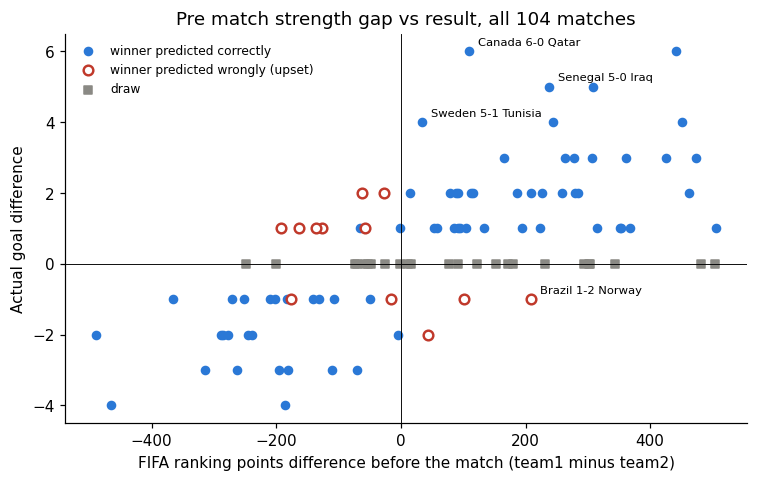

In [29]:
oos = np.zeros(len(df))
for a, b in KFold(n_splits=5, shuffle=True, random_state=42).split(df):
    oos[b] = LinearRegression().fit(df.iloc[a][SELECTED], y_all.iloc[a]).predict(df.iloc[b][SELECTED])
df["predicted"], df["error"] = oos.round(2), (y_all - oos).round(2)

decisive = y_all != 0
hit = np.sign(oos[decisive]) == np.sign(y_all[decisive])
print(f"Winner predicted correctly in {hit.sum()} of {decisive.sum()} decisive matches ({hit.mean():.1%})")
draws = ~decisive
print(f"Draws: {draws.sum()} matches; mean |prediction| in draws = {np.abs(oos[draws]).mean():.2f} goals")

df["phase"] = np.where(df["stage"] == "First Stage", "Group stage", "Knockout")
display(df.groupby("phase")["error"].agg(rows="size", MAE=lambda e: e.abs().mean(),
                                         RMSE=lambda e: np.sqrt((e ** 2).mean())).round(3))
misses = df.reindex(df["error"].abs().sort_values(ascending=False).index)
display(misses[["date", "stage", "team1", "team2", "team1_goals", "team2_goals", "predicted", "error"]].head(6))

# Storytelling figure: the strength gap explains most results; labelled points are the biggest surprises.
fig, ax = plt.subplots(figsize=(8, 4.6))
ok = np.sign(oos) == np.sign(y_all)
ax.scatter(df.loc[ok & decisive, "fifa_points_diff"], y_all[ok & decisive], s=28, color=BLUE, label="winner predicted correctly")
ax.scatter(df.loc[~ok & decisive, "fifa_points_diff"], y_all[~ok & decisive], s=40, facecolor="white",
           edgecolor="#c0392b", linewidth=1.6, label="winner predicted wrongly (upset)")
ax.scatter(df.loc[draws, "fifa_points_diff"], y_all[draws], s=22, marker="s", color=GREY, label="draw")
ax.axhline(0, color="black", linewidth=0.6)
ax.axvline(0, color="black", linewidth=0.6)
for _, r in misses.head(4).iterrows():
    ax.annotate(f"{r.team1} {r.team1_goals}-{r.team2_goals} {r.team2}", (r.fifa_points_diff, r.goal_difference),
                xytext=(6, 4), textcoords="offset points", fontsize=7.5)
ax.set(xlabel="FIFA ranking points difference before the match (team1 minus team2)",
       ylabel="Actual goal difference", title="Pre match strength gap vs result, all 104 matches")
ax.legend(frameon=False, fontsize=8, loc="upper left")
fig.savefig(OUT / "figures" / "story_strength_vs_result.png", bbox_inches="tight")
plt.show()

## 23. Save the key results

In [30]:
best_alt = comparison["CV RMSE"].idxmin()
lines = [
    f"Linear Regression {'2.1' if TARGET == 'goal_difference' else '2.2'}: target = {TARGET}",
    f"Selected 8: {', '.join(SELECTED)}",
    f"Full sample OLS: R2 = {ols.rsquared:.3f}, adjusted R2 = {ols.rsquared_adj:.3f}, F = {ols.fvalue:.2f}, p(F) = {ols.f_pvalue:.2e}",
    "Test set (model): " + ", ".join(f"{k} = {v:.3f}" for k, v in results["Linear regression"].items()),
    "Test set (baseline): " + ", ".join(f"{k} = {v:.3f}" for k, v in results["Baseline (mean)"].items()),
    f"Nested CV RMSE: model {nested[:, 0].mean():.3f} vs baseline {nested[:, 1].mean():.3f}; R2 {nested[:, 2].mean():.3f}",
    f"Lowest CV RMSE among alternatives: {best_alt} ({comparison.loc[best_alt, 'CV RMSE']})",
    f"Optimisation: {OPT_NAME}; CV RMSE {opt_table.loc[OPT_NAME, 'CV RMSE']} vs OLS {opt_table.iloc[0]['CV RMSE']} "
    f"({opt_table.loc[OPT_NAME, 'change vs step 0 (%)']}%, corrected p = {opt_table.loc[OPT_NAME, 'p value vs step 0 (corrected)']})",
    f"Competing algorithms: best = {best} (CV RMSE {algo_table.loc[best, 'CV RMSE']})",
    f"Recommendation: {recommendation}",
    f"Significant at 0.05 (classical): {', '.join(significant) if significant else 'none'}",
    "Assumption checks: " + "; ".join(f"{c} = {v}" for c, v in zip(tests['check'], tests['value'])),
]
(OUT / "results.txt").write_text("\n".join(lines))
print("\n".join(lines))

Linear Regression 2.1: target = goal_difference
Selected 8: fifa_points_diff, wc_experience_diff, prev_linebreaks_diff, prev_shots_against_diff, prev_goals_against_diff, prev_shots_diff, strong_confederation_diff, prev_xg_diff
Full sample OLS: R2 = 0.472, adjusted R2 = 0.428, F = 10.62, p(F) = 1.52e-10
Test set (model): MAE = 1.353, MSE = 3.421, RMSE = 1.850, NRMSE = 0.206, R2 = 0.177, Adjusted R2 = -0.372
Test set (baseline): MAE = 1.588, MSE = 4.157, RMSE = 2.039, NRMSE = 0.227, R2 = -0.001, Adjusted R2 = -0.668
Nested CV RMSE: model 1.633 vs baseline 2.009; R2 0.276
Lowest CV RMSE among alternatives: Strength only (1.587)
Optimisation: Step 3: Yeo-Johnson + Ridge (alpha tuned); CV RMSE 1.5857 vs OLS 1.6413 (-3.3878%, corrected p = 0.2591)
Competing algorithms: best = Optimised linear model (Block 19) (CV RMSE 1.586)
Recommendation: The optimised linear model has the lowest cross validated RMSE (1.586); the closest competitor, k nearest neighbours (k = 10), is 0.018 goals worse (corr

## Interpretation notes and limits
* **Association, not cause.** Coefficients describe how predictions change with a variable while the other seven
  are held fixed. They do not show that the variable causes goals.
* **Sample size.** 104 matches is small for 8 variables,
  so the single test split is noisy. The nested cross validation (Block 20) is the most reliable performance estimate.
* **First matches.** Every tournament form variable is 0 in a team's first match, so early predictions rest on
  pre tournament strength alone.
* **Shared information.** Correlated predictors share explanatory power, so a non significant coefficient does not
  prove a variable is useless. Block 20 shows how consistently each variable is chosen.
* **Discrete target.** Goal difference is a whole number, while the model predicts a continuous value.